# 4. Describing a dataset (EDA)

In [1]:
import tempfile
from pathlib import Path

import pandas as pd

from perspective_audit import run_dataset
from perspective_audit.toy import toy_ratings, toy_spec

pd.set_option("display.width", 160)
result = run_dataset(toy_spec(), raw=toy_ratings())        # the toy dataset: 60 texts, 24 annotators, gender / politics / age

In [2]:
from perspective_audit import eda_tables

tables = eda_tables(result)
list(tables)

['preprocessing',
 'overview',
 'rating_distribution',
 'funnel',
 'groups',
 'au_labels',
 'text_length']

In [3]:
tables["preprocessing"]

,count,% of raw ratings
step,,
ratings (raw),1440,100.0
removed by the prefilter,0,0.0
removed for an excluded group value (any dimension),0,0.0
ratings (clean),1440,100.0
texts (raw),60,NaN
texts (clean),60,NaN
texts lost,0,NaN
ratings with an excluded gender value (after the prefilter),0,0.0
ratings with an excluded politics value (after the prefilter),0,0.0


The funnel: what happens to the texts of each characteristic.

In [4]:
tables["funnel"]

reason,texts,not polarised,too few groups,a group is not unimodal,AU,AU %
gender,60,20,0,20,20,33.3
politics,60,20,0,20,20,33.3
age,60,20,0,40,0,0.0


In [5]:
tables["groups"]

ratings  mean rating  toxic %  AU ratings  AU mean rating  AU toxic %  kept in AU analysis
dimension group                                                                                            
gender    man        720         3.04     50.0         240            3.09        50.0                 True
          woman      720         3.00     50.0         240            3.00        50.0                 True
politics  left       720         3.04     50.0         240            3.02        50.0                 True
          right      720         3.00     50.0         240            2.96        50.0                 True
age       old        720         3.02     50.0           0             NaN         NaN                 True
          young      720         3.02     50.0           0             NaN         NaN                 True

## Figures

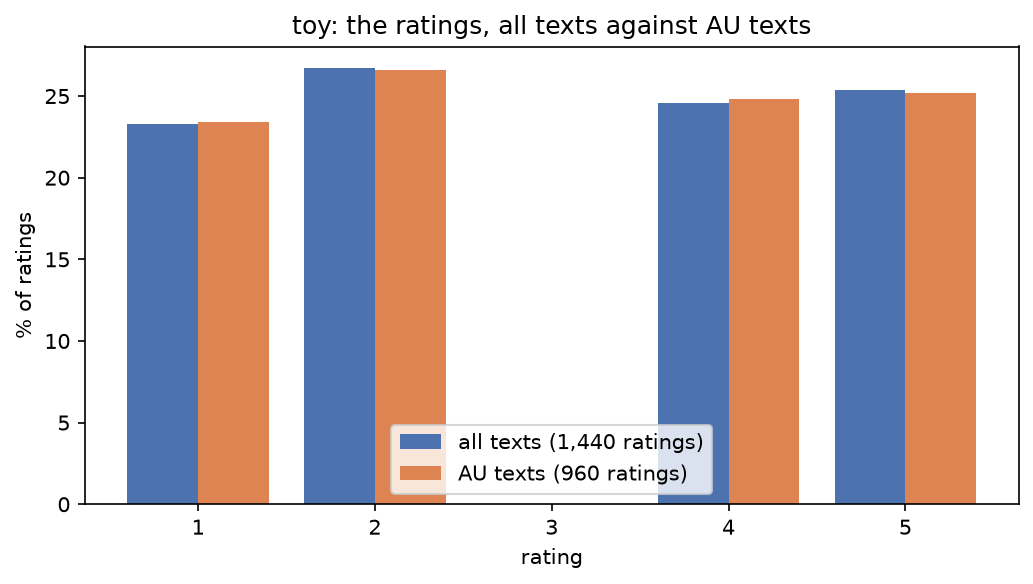

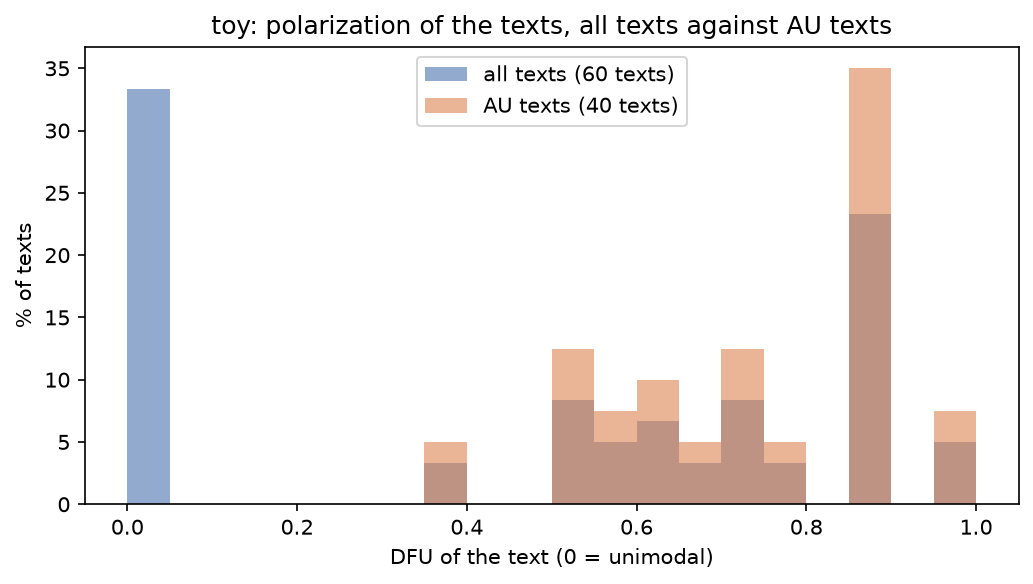

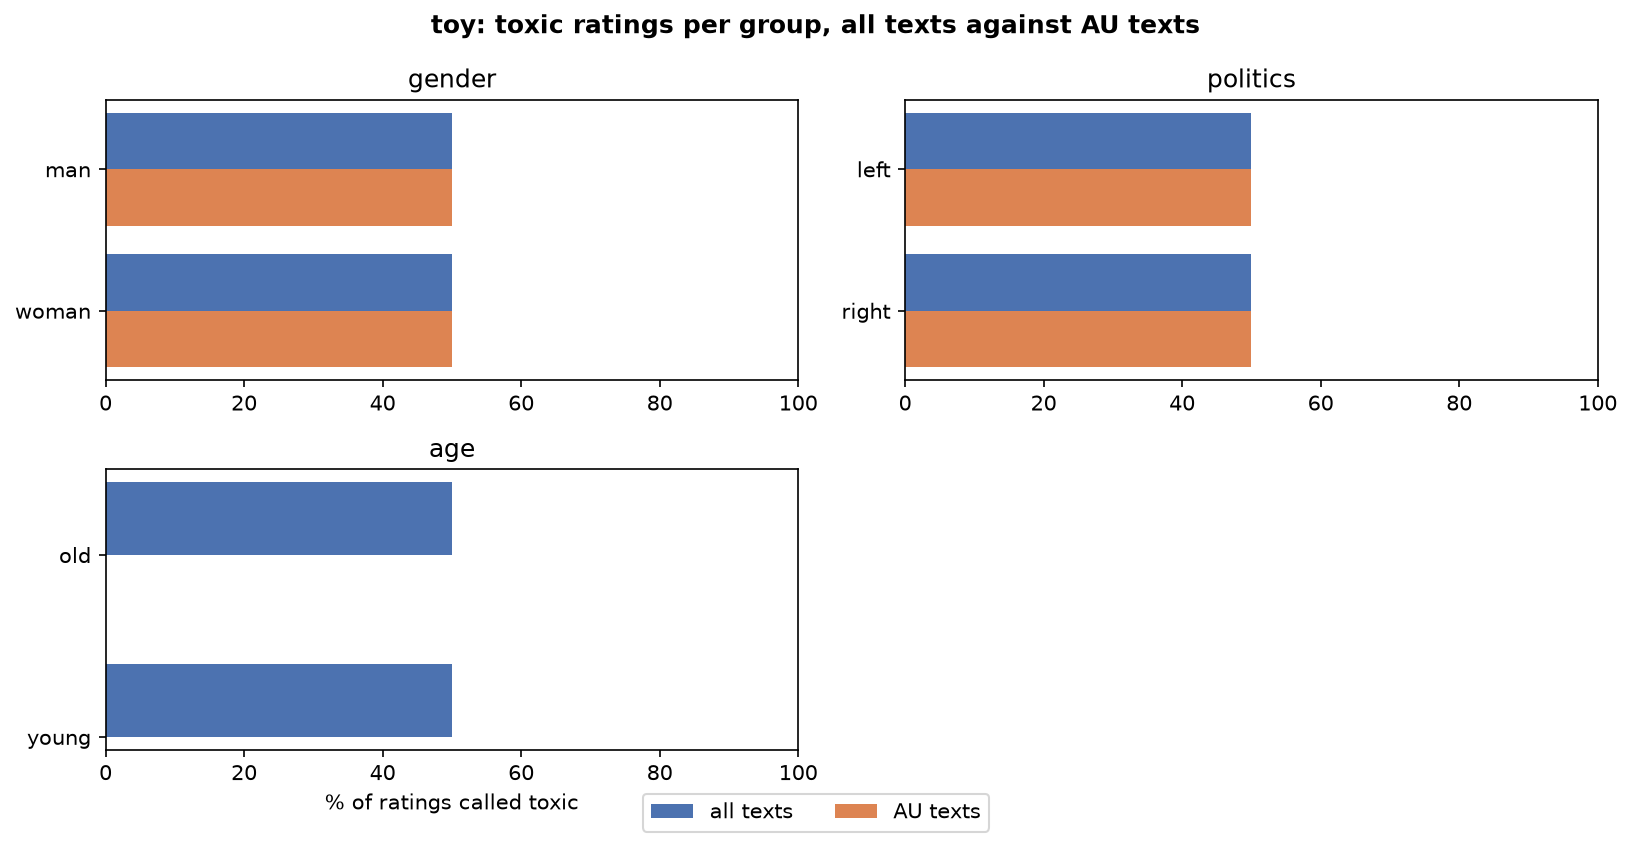

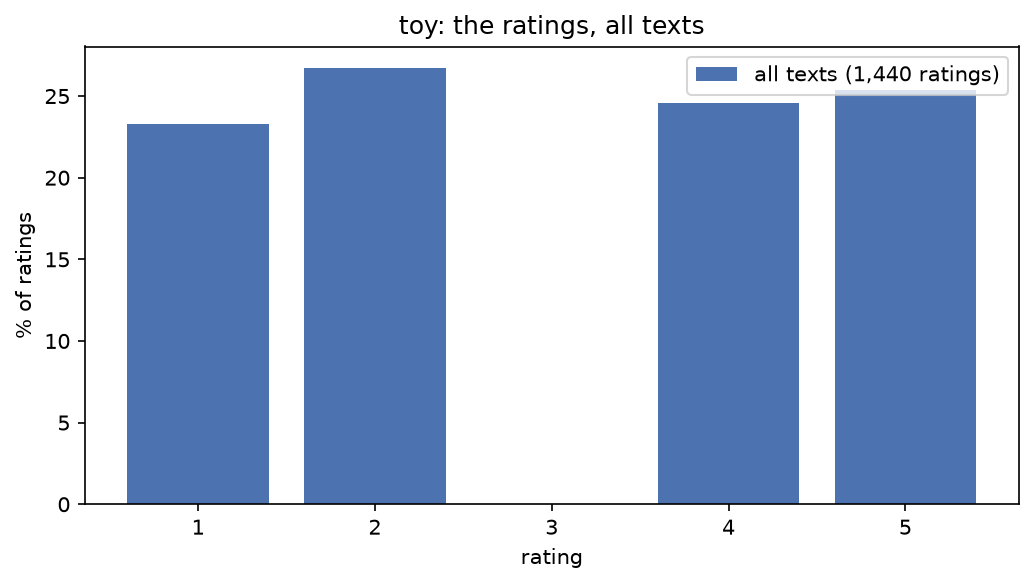

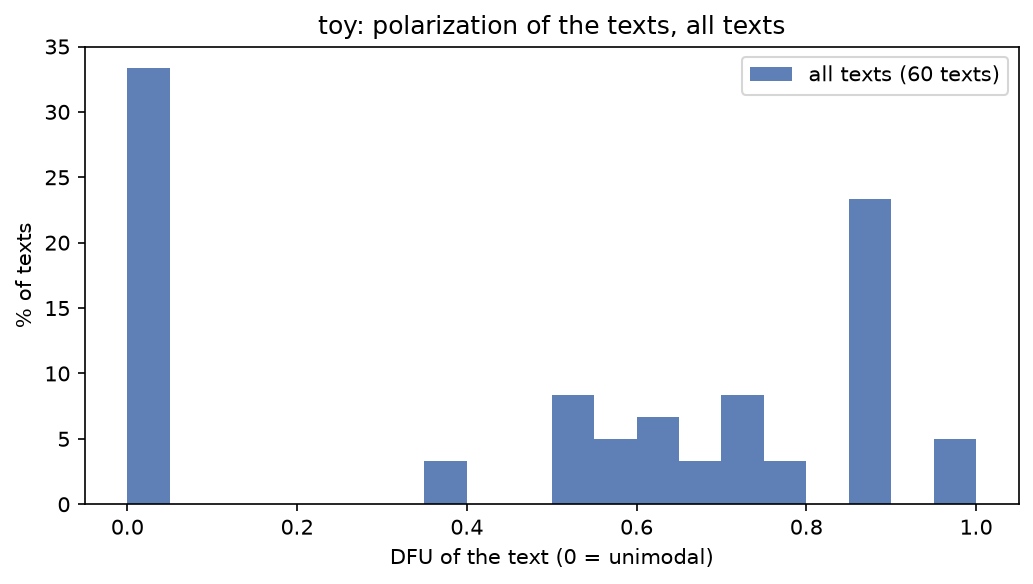

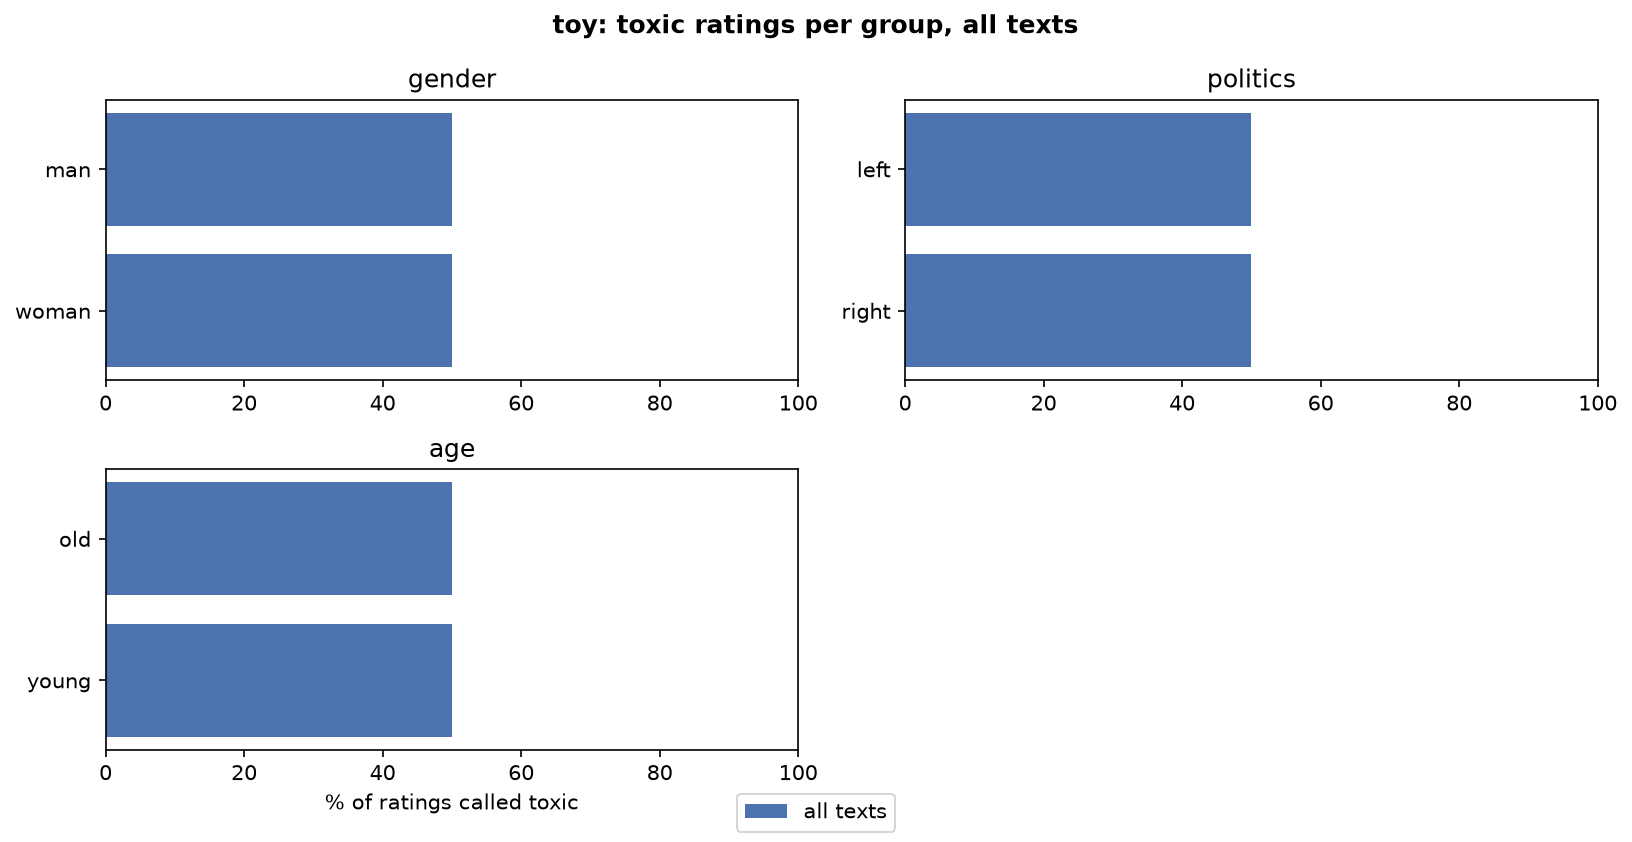

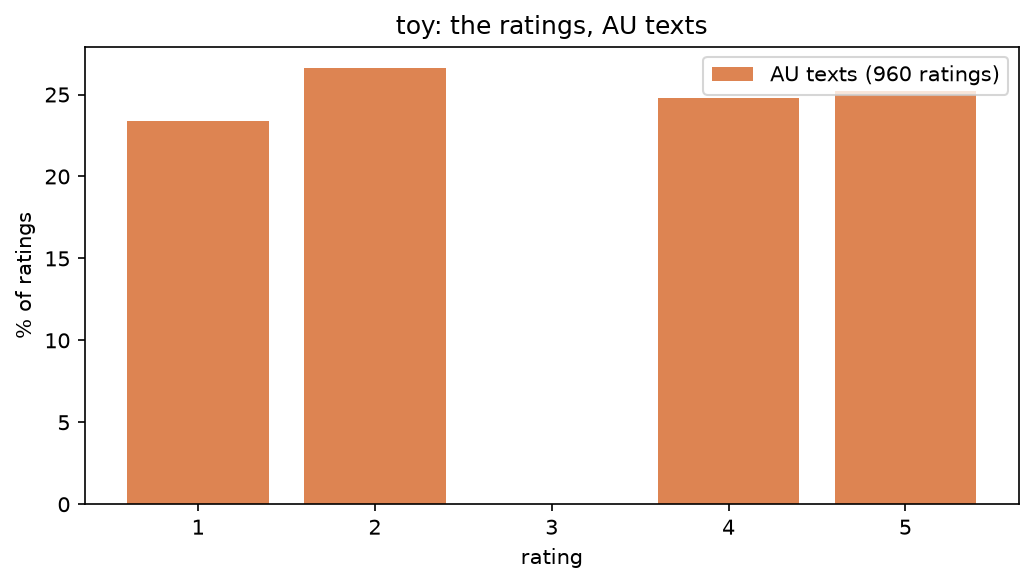

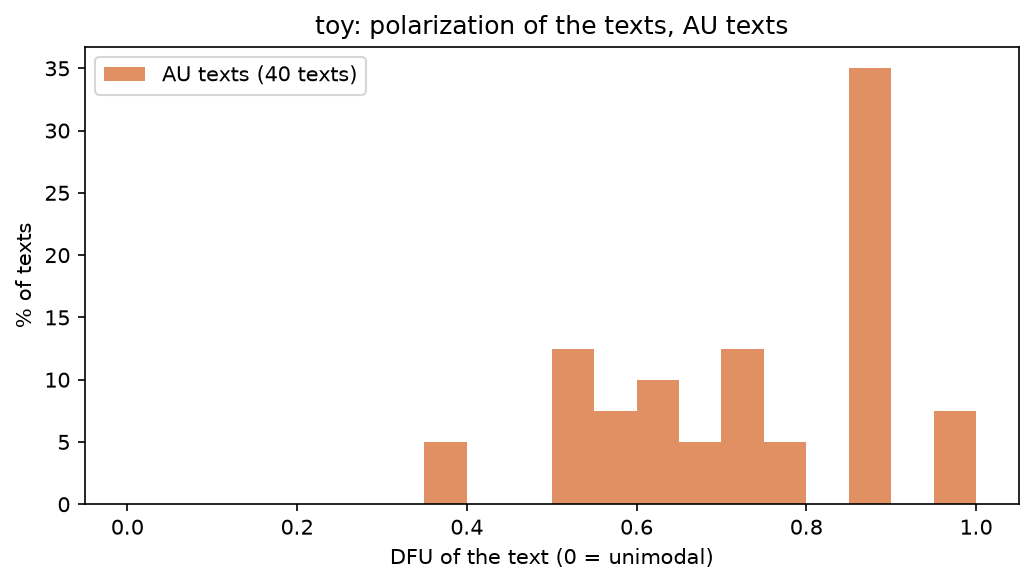

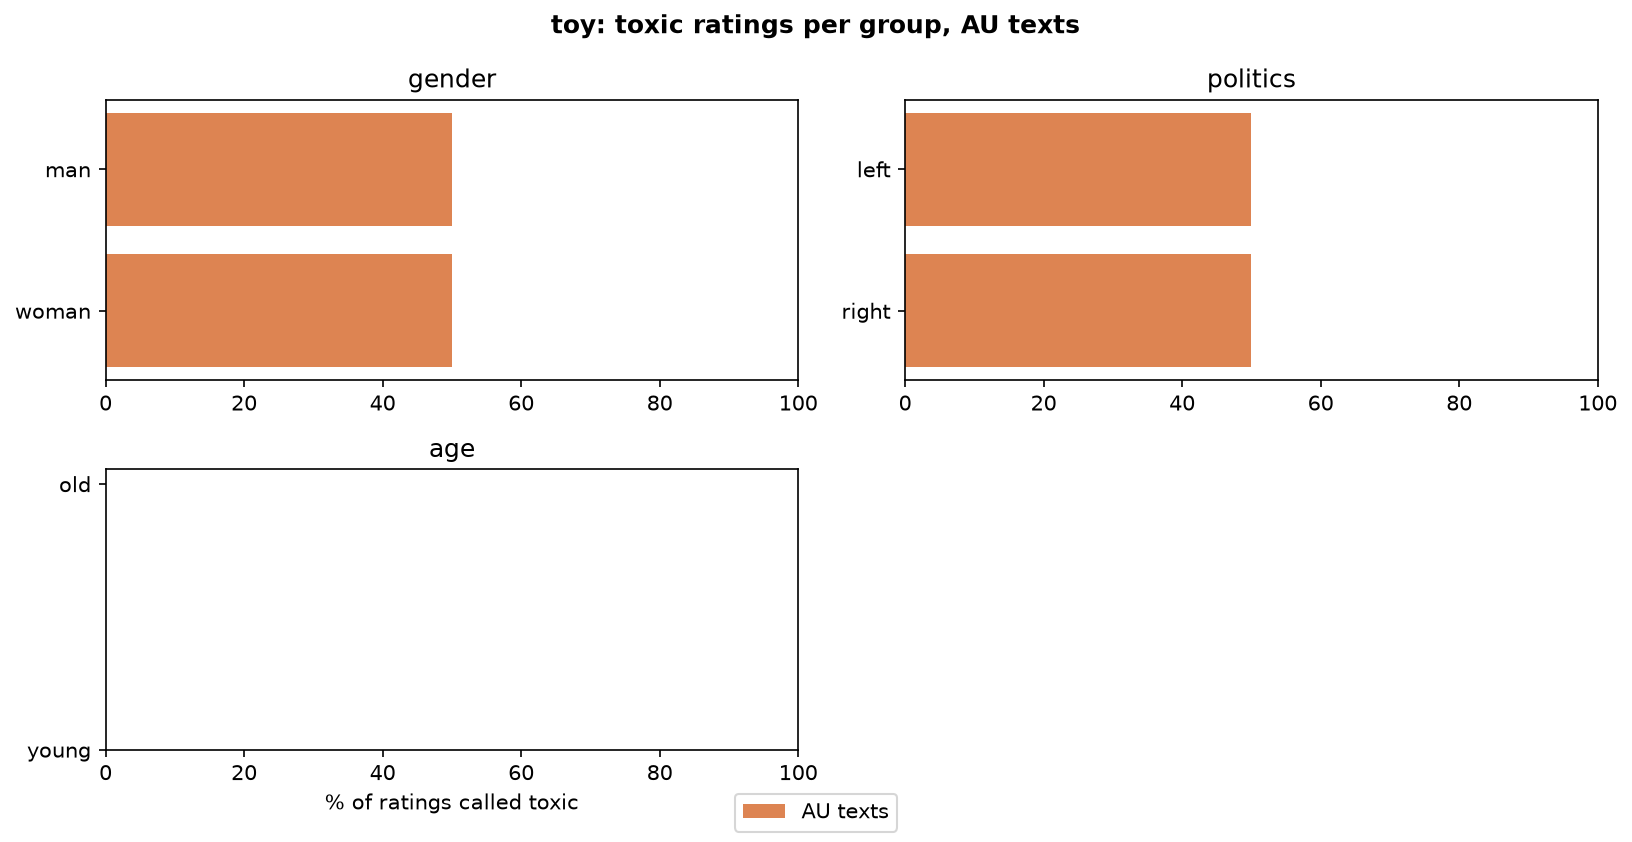

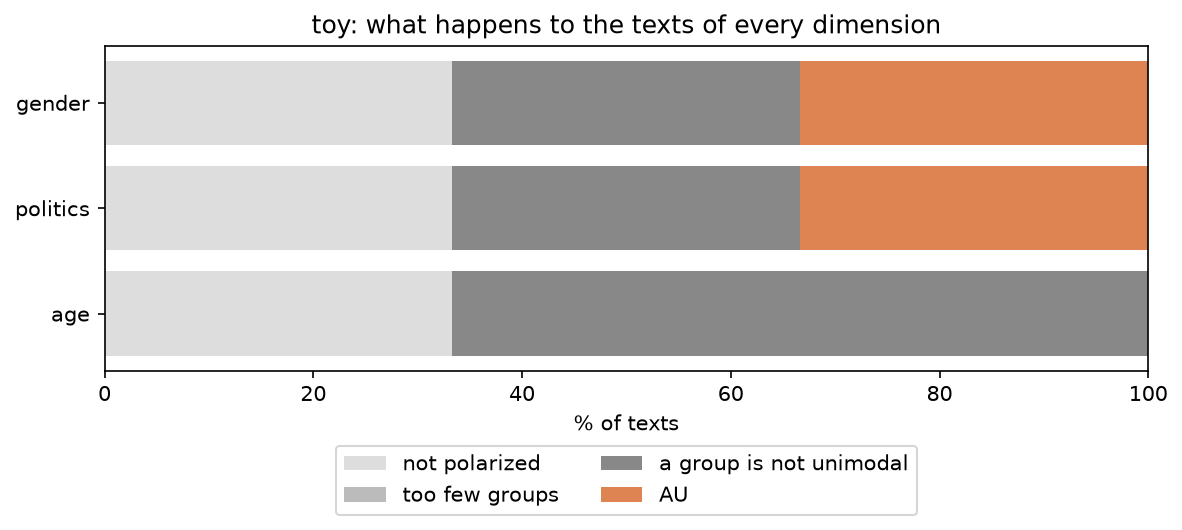

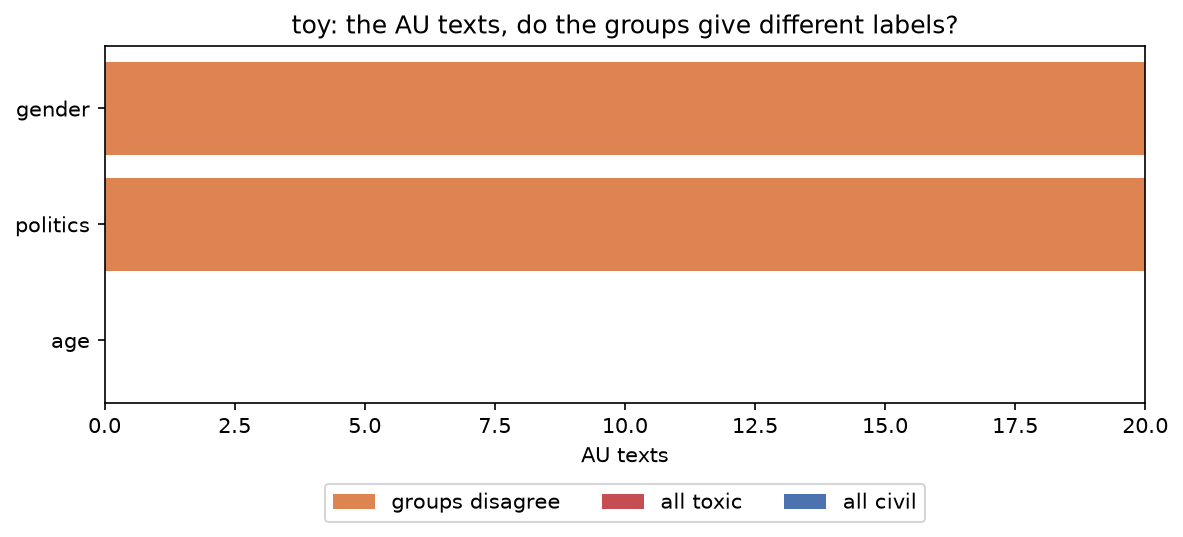

In [6]:
from IPython.display import Image, display
from perspective_audit import save_eda

folder = Path(tempfile.mkdtemp())
saved = save_eda(result, folder)
for path in saved.values():
    if path.suffix == ".png":
        display(Image(filename=str(path)))